##### Copyright 2018 The TensorFlow Authors.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

In [2]:
#@title MIT License
#
# Copyright (c) 2017 François Chollet
#
# Permission is hereby granted, free of charge, to any person obtaining a
# copy of this software and associated documentation files (the "Software"),
# to deal in the Software without restriction, including without limitation
# the rights to use, copy, modify, merge, publish, distribute, sublicense,
# and/or sell copies of the Software, and to permit persons to whom the
# Software is furnished to do so, subject to the following conditions:
#
# The above copyright notice and this permission notice shall be included in
# all copies or substantial portions of the Software.
#
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
# THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
# FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
# DEALINGS IN THE SOFTWARE.

# Basic classification: Classify images of objects

This project investigates supervised multiclass image classification using the CIFAR-10 dataset. Convolutional neural networks are trained to classify low-resolution colour images into ten object categories. 

Model performance is evaluated using validation accuracy, test accuracy, training time, confusion matrices and per-class precision, recall and F1-scores. Experiments with model architecture, regularisation and data augmentation are used to investigate performance and generalisation.

This guide uses [tf.keras](https://www.tensorflow.org/guide/keras), a high-level API to build and train models in TensorFlow.

This guide uses [kerastuner](https://keras.io/keras_tuner/getting_started/) for hyperparameter tuning of keras models.

This guide uses [numpy](https://numpy.org/doc/stable/user/) for numerical calculations and working with arrays of data.

This guide uses [matplotlib](https://matplotlib.org/stable/users/explain/quick_start.html) to create graphs, charts and visualisations.

This guide uses [time](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/nbextensions/execute_time/readme.html) to measure how long code takes to execute.

In [3]:
%pip install tensorflow keras-tuner numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import keras
import keras_tuner as kt
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time


## Import the CIFAR-10 dataset

This guide uses the CIFAR-10 dataset, which contains 60,000 colour images in 10 categories. The images show individual articles of objects, each measuring 32 x 32 pixels, as seen here:

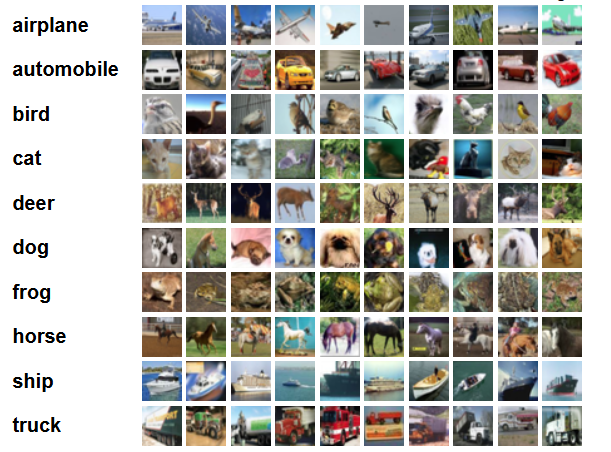

**Figure 1. CIFAR-10 sample images (Toronto.edu, 2026)**

CIFAR-10 is a commonly used dataset for image classification in computer vision. It contains colour images of everyday objects and animals, such as aeroplanes, cars, birds, cats, dogs and ships. The dataset is often used to develop and test machine learning models that can recognise and classify different types of objects in images.

This project uses CIFAR-10 because it provides a more challenging classification task than simpler datasets, such as MNIST, which contains images of handwritten digits. The images in CIFAR-10 have a resolution of 32 × 32 pixels, making the dataset suitable for experimenting with different neural network architectures, particularly convolutional neural networks (CNNs). It is also useful for testing and comparing models to see how well they learn to recognise visual features.

The dataset contains 60,000 images across 10 different classes. Of these, 50,000 images are used to train the model, while the remaining 10,000 images are used to evaluate its performance on data it has not seen during training. The CIFAR-10 dataset can be loaded directly through TensorFlow using its Keras datasets module. This allows the images and their corresponding labels to be imported ready for preprocessing and model training. Import and [load the CIFAR-10 data](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10/load_data) directly from TensorFlow:

In [5]:
# ============================================================
# 2. LOAD CIFAR-10 DATASET
# ============================================================

# Select the CIFAR-10 dataset from TensorFlow/Keras
cifar10 = tf.keras.datasets.cifar10

# Load the training and test datasets
(train_images, train_labels), (test_images, test_labels) = (
    cifar10.load_data()
)


## Inspect the Dataset Shapes

This section examines the dimensions of the CIFAR-10 training and test datasets. Checking the shapes helps confirm the number of images, the dimensions of each image and the structure of the corresponding labels before training begins.

In [6]:
# ============================================================
# 3. INSPECT DATASET SHAPES
# ============================================================

print("Training images shape:", train_images.shape)
print("Training labels shape:", train_labels.shape)
print("Test images shape:", test_images.shape)
print("Test labels shape:", test_labels.shape)

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


## Inspect Data Types and Pixel Values

This section checks the data types used to store the images and labels, along with the minimum and maximum pixel values. These checks help identify the format of the data and determine whether any pre-processing is needed before feeding the images into the model.

In [7]:
# ============================================================
# 4. INSPECT DATA TYPES AND PIXEL VALUES
# ============================================================

print("\nImage data type:", train_images.dtype)
print("Label data type:", train_labels.dtype)
print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())


Image data type: uint8
Label data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


## Display Sample CIFAR-10 Images

This section displays a selection of images from the training dataset, along with their corresponding class names. Viewing the images provides a better understanding of the data and helps confirm that the labels match the objects shown.

<table>
  <tr>
    <th>Label</th>
    <th>Class</th>
  </tr>
  <tr>
    <td>0</td>
    <td>Airplane</td>
  </tr>
  <tr>
    <td>1</td>
    <td>Automobile</td>
  </tr>
    <tr>
    <td>2</td>
    <td>Bird</td>
  </tr>
    <tr>
    <td>3</td>
    <td>Cat</td>
  </tr>
    <tr>
    <td>4</td>
    <td>Deer</td>
  </tr>
    <tr>
    <td>5</td>
    <td>Dog</td>
  </tr>
    <tr>
    <td>6</td>
    <td>Frog</td>
  </tr>
    <tr>
    <td>7</td>
    <td>Horse</td>
  </tr>
    <tr>
    <td>8</td>
    <td>Ship</td>
  </tr>
    <tr>
    <td>9</td>
    <td>Truck</td>
  </tr>
</table>

Each image is mapped to a single label. Since the *class names* are not included with the dataset, store them here to use later when plotting the images:

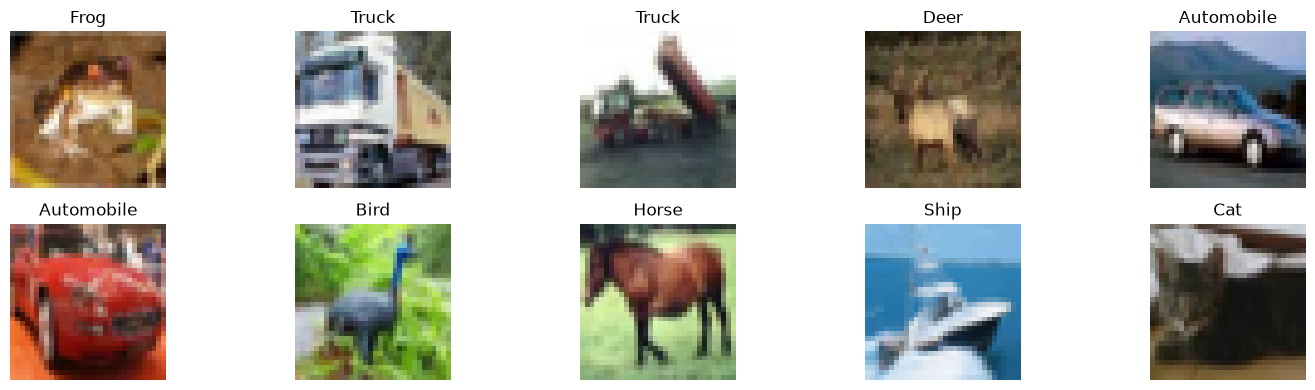

In [8]:
# ============================================================
# 5. DISPLAY SAMPLE CIFAR-10 IMAGES
# ============================================================

# CIFAR-10 class names, in label order
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Create a figure containing 10 sample images
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Display the image
    plt.imshow(train_images[i])

    # Convert the label from a one-element array to an integer
    label = int(train_labels[i][0])

    # Display the corresponding class name
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Pre-process the Data

This section prepares the image data for training by converting the pixel values to floating-point numbers and scaling them from a range of 0–255 to 0–1. Normalising the pixel values helps the neural network work with a consistent input range during training.

In [9]:
# ============================================================
# 6. PREPROCESS THE DATA
# ============================================================
#
# The original notebook scales pixel values from:
#
# 0 - 255
#
# to:
#
# 0 - 1
#
# by dividing by 255.
# ============================================================

train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

# Print the shape after preprocessing.
print("Training images:", train_images.shape)
print("Test images:", test_images.shape)

Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


## Define the CNN Model for Hyperparameter Tuning

This section defines a convolutional neural network (CNN) with adjustable hyperparameters. The model uses convolutional and pooling layers to learn visual features, followed by dense layers to classify images into the ten CIFAR-10 categories. The learning rate, filter counts, kernel sizes and number of dense-layer neurons can be adjusted during tuning.

In [10]:
# ============================================================
# 7. DEFINE THE CNN MODEL FOR HYPERPARAMETER TUNING
# ============================================================

def build_model(hp):

    # Create a sequential CNN architecture.
    model = keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3)),

        # First convolutional layer.
        keras.layers.Conv2D(
            filters=hp.Int(
                "conv_1_filter",
                min_value=32,
                max_value=128,
                step=32
            ),
            kernel_size=hp.Choice(
                "conv_1_kernel",
                values=[3, 5]
            ),
            activation="relu",
            padding="same"
        ),

        # Reduce the spatial dimensions.
        keras.layers.MaxPooling2D(pool_size=(2, 2)),

        # Second convolutional layer.
        keras.layers.Conv2D(
            filters=hp.Int(
                "conv_2_filter",
                min_value=32,
                max_value=64,
                step=32
            ),
            kernel_size=hp.Choice(
                "conv_2_kernel",
                values=[3, 5]
            ),
            activation="relu",
            padding="same"
        ),

        keras.layers.MaxPooling2D(pool_size=(2, 2)),

        # Convert feature maps into a feature vector.
        keras.layers.Flatten(),

        # Fully connected classification layer.
        keras.layers.Dense(
            units=hp.Int(
                "dense_1_units",
                min_value=64,
                max_value=128,
                step=32
            ),
            activation="relu"
        ),

        # Output probabilities for the 10 CIFAR-10 classes.
        keras.layers.Dense(10, activation="softmax")
    ])

    # Select the learning rate during hyperparameter tuning.
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0001]
    )

    # Compile the model for multi-class classification.
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Search for Suitable Hyperparameters

This section uses KerasTuner's RandomSearch method to test different combinations of hyperparameters. Each candidate model is trained for a small number of epochs, and its validation accuracy is used to compare configurations. The best-performing configuration is then selected for further training.

In [11]:
# ============================================================
# 8. SEARCH FOR GOOD HYPERPARAMETERS
# ============================================================

# RandomSearch tests different combinations of hyperparameters.
tuner_search = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=5,
    executions_per_trial=1,
    directory="output",
    project_name="CIFAR10_CNN",
    overwrite=True,
    seed=42
)

# Train each candidate for three epochs.
# Use part of the training data for validation.
tuner_search.search(
    train_images,
    train_labels,
    epochs=3,
    validation_split=0.1,
    batch_size=64,
    verbose=1
)

# Display the best hyperparameter configuration.
best_hp = tuner_search.get_best_hyperparameters(
    num_trials=1
)[0]

print("\nBest hyperparameters:")
for name, value in best_hp.values.items():
    print(f"{name}: {value}")

Trial 5 Complete [00h 00m 52s]
val_accuracy: 0.6854000091552734

Best val_accuracy So Far: 0.6854000091552734
Total elapsed time: 00h 05m 58s

Best hyperparameters:
conv_1_filter: 32
conv_1_kernel: 3
conv_2_filter: 64
conv_2_kernel: 5
dense_1_units: 128
learning_rate: 0.001


## Train the Selected CNN Model

This section builds a new CNN using the best hyperparameters identified during the search. The model is then trained for ten epochs, with part of the training data reserved for validation. The training duration is also recorded to help assess the time required to train the selected model.

In [12]:
# ============================================================
# 9. TRAIN THE SELECTED MODEL
# ============================================================

# Build a fresh model using the best hyperparameters.
model = build_model(best_hp)

# Add a timer to measure training time.
cnn_start_time = time.time()

# Train for ten epochs from the beginning.
history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

cnn_training_time = time.time() - cnn_start_time

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.4621 - loss: 1.4888 - val_accuracy: 0.5484 - val_loss: 1.2485
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.6090 - loss: 1.1109 - val_accuracy: 0.6214 - val_loss: 1.1094
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.6638 - loss: 0.9626 - val_accuracy: 0.6690 - val_loss: 0.9524
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.6966 - loss: 0.8662 - val_accuracy: 0.7112 - val_loss: 0.8586
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.7217 - loss: 0.7921 - val_accuracy: 0.7038 - val_loss: 0.8731
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.7478 - loss: 0.7228 - val_accuracy: 0.7120 - val_loss: 0.8542
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.7659 - loss: 0.6644 - val_accuracy: 0.7066 - val_loss: 0.9007
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - accuracy: 0.7893 - loss: 0.6029 - 

## Reserve the Test Dataset

The test dataset is kept separate from model selection and hyperparameter tuning. It is reserved for the final evaluation so that the selected model can be assessed using images it has not encountered during training or validation.

In [13]:
# ============================================================
# 10. HOLD BACK THE TEST SET
# ============================================================
# Do not evaluate candidate models on the test set here. The test set
# is reserved for the final evaluation after model selection.

## Plot Training and Validation Accuracy

This section plots the training and validation accuracy across the training epochs. Comparing the two curves helps show how well the model learns from the training data and whether its performance improves on unseen validation images.

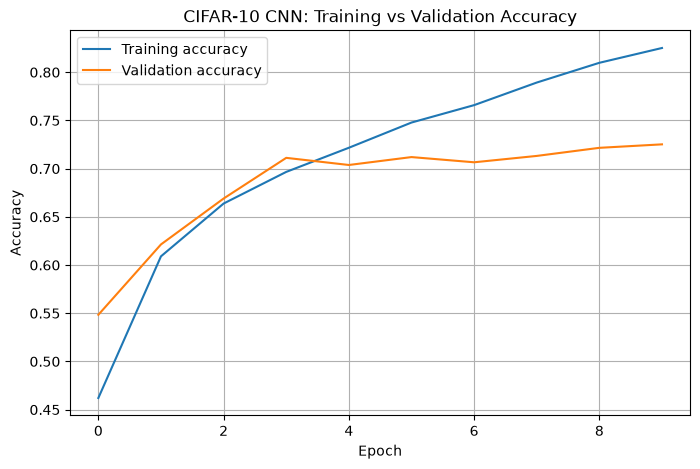

In [14]:
# ============================================================
# 11. PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CIFAR-10 CNN: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Plot Training and Validation Loss

This section displays the training and validation loss across the epochs. Loss measures how far the model's predictions are from the correct labels. Comparing both curves helps assess the model's learning progress and identify possible signs of overfitting.

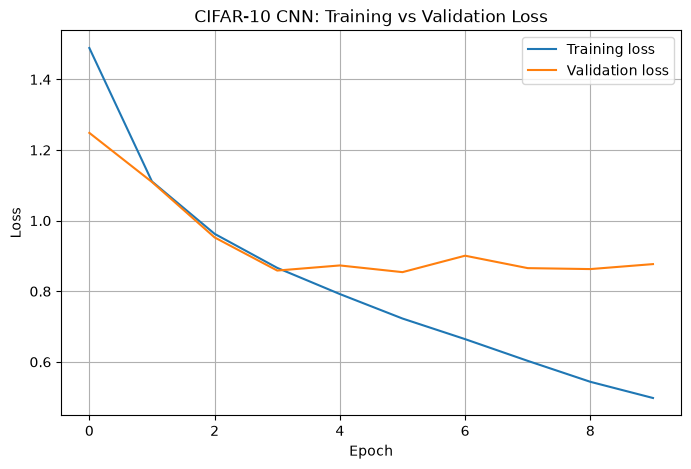

In [15]:
# ============================================================
# 12. PLOT TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAR-10 CNN: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Create Functions for Training and Evaluating Models

This section defines reusable functions for creating, training and evaluating neural network models. The functions allow different activation functions, optimisers and neuron counts to be tested while keeping the main training settings consistent. Training time and the best validation accuracy are recorded for each experiment.

In [16]:
# ============================================================
# 13. FUNCTION TO TRAIN AND EVALUATE A MODEL
# ============================================================

def create_model(activation="relu", optimiser="adam", neurons=128):
    model = keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3)),
        keras.layers.Flatten(),
        keras.layers.Dense(neurons, activation=activation),
        keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=optimiser,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def train_and_evaluate(
    name,
    activation="relu",
    optimiser="adam",
    neurons=128,
    epochs=10
):
    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    model = create_model(
        activation=activation,
        optimiser=optimiser,
        neurons=neurons
    )

    starting_time = time.time()

    history = model.fit(
        train_images,
        train_labels,
        epochs=epochs,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    training_time = time.time() - starting_time

    # Record the best validation accuracy for model selection.
    # The held-out test set is deliberately not used in this function.
    best_val_accuracy = max(history.history["val_accuracy"])

    print(f"Training time: {training_time:.2f} seconds")
    print(f"Best validation accuracy: {best_val_accuracy:.4f}")

    return {
        "name": name,
        "model": model,
        # The model already outputs softmax probabilities.
        "probability_model": model,
        "history": history,
        "activation": activation,
        "optimiser": optimiser,
        "neurons": neurons,
        "training_time": training_time,
        "val_accuracy": best_val_accuracy
    }

## Establish the Baseline Model

This section establishes a baseline model using ReLU activation, the Adam optimiser and 128 neurons in the hidden layer. The model is trained for ten epochs to provide a reference point for comparing the results of subsequent experiments.

In [17]:
# ============================================================
# 14. BASELINE MODEL
# ============================================================
#
# Original configuration from the notebook:
#
# ReLU
# Adam
# 128 neurons
# 10 epochs
# ============================================================

baseline = train_and_evaluate(
    name='Baseline',
    activation='relu',
    optimiser='adam',
    neurons=128,
    epochs=10
)


MODEL: Baseline
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3154 - loss: 1.9214 - val_accuracy: 0.3412 - val_loss: 1.8316
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3716 - loss: 1.7722 - val_accuracy: 0.3620 - val_loss: 1.7777
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3908 - loss: 1.7161 - val_accuracy: 0.3842 - val_loss: 1.7305
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4064 - loss: 1.6742 - val_accuracy: 0.4114 - val_loss: 1.6738
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4166 - loss: 1.6501 - val_accuracy: 0.4168 - val_loss: 1.6479
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4253 - loss: 1.6188 - val_accuracy: 0.4142 - val_loss: 1.6580
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4304 - loss: 1.6078 - val_accuracy: 0.4204 - val_loss: 1.6460
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4342 - loss: 1.5966 -

## Compare Activation Functions

This section investigates how different activation functions affect model performance. The experiments compare ReLU, Tanh and ELU while keeping the optimiser, number of neurons and number of epochs consistent. This helps assess whether the choice of activation function influences the model's ability to learn from the images.

In [18]:
# ============================================================
# 15. ACTIVATION FUNCTION EXPERIMENTS
# ============================================================
#
# Keep:
#
# Optimiser = Adam
# Neurons = 128
#
# Change:
#
# ReLU
# Tanh
# ELU
# ============================================================

# -------------------------
# Tanh
# -------------------------

tanh_model = train_and_evaluate(
    name='Tanh',
    activation='tanh',
    optimiser='adam',
    neurons=128,
    epochs=10
)

# -------------------------
# ELU
# -------------------------

elu_model = train_and_evaluate(
    name='ELU',
    activation='elu',
    optimiser='adam',
    neurons=128,
    epochs=10
)


MODEL: Tanh
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3038 - loss: 1.9613 - val_accuracy: 0.3072 - val_loss: 1.9143
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3487 - loss: 1.8205 - val_accuracy: 0.3492 - val_loss: 1.8081
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3635 - loss: 1.7770 - val_accuracy: 0.3602 - val_loss: 1.7929
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3703 - loss: 1.7635 - val_accuracy: 0.3354 - val_loss: 1.8135
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3781 - loss: 1.7389 - val_accuracy: 0.3810 - val_loss: 1.7439
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3851 - loss: 1.7168 - val_accuracy: 0.3696 - val_loss: 1.7519
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3921 - loss: 1.7027 - val_accuracy: 0.3784 - val_loss: 1.7438
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3953 - loss: 1.6901 - val

## Compare Optimisers

This section examines the effect of different optimisation algorithms on model training. Adam, SGD, RMSprop and Adagrad are compared while keeping the activation function, number of neurons and number of epochs consistent. The results help show how the choice of optimiser affects validation accuracy and training time.

In [19]:
# ============================================================
# 16. OPTIMISER EXPERIMENTS
# ============================================================
#
# Keep:
#
# Activation = ReLU
# Neurons = 128
#
# Change:
#
# Adam
# SGD
# RMSprop
# Adagrad
# ============================================================


# -------------------------
# SGD
# -------------------------

sgd_model = train_and_evaluate(
    name='SGD',
    activation='relu',
    optimiser='sgd',
    neurons=128,
    epochs=10
)


# -------------------------
# RMSprop
# -------------------------

rmsprop_model = train_and_evaluate(
    name='RMSprop',
    activation='relu',
    optimiser='rmsprop',
    neurons=128,
    epochs=10
)


# -------------------------
# Adagrad
# -------------------------

adagrad_model = train_and_evaluate(
    name='Adagrad',
    activation='relu',
    optimiser='adagrad',
    neurons=128,
    epochs=10
)


MODEL: SGD
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3092 - loss: 1.9478 - val_accuracy: 0.2616 - val_loss: 2.0455
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3698 - loss: 1.7896 - val_accuracy: 0.3398 - val_loss: 1.8431
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3994 - loss: 1.7212 - val_accuracy: 0.3418 - val_loss: 1.8733
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4158 - loss: 1.6728 - val_accuracy: 0.3574 - val_loss: 1.8269
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4292 - loss: 1.6352 - val_accuracy: 0.3444 - val_loss: 1.8421
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4416 - loss: 1.6059 - val_accuracy: 0.3726 - val_loss: 1.7673
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4488 - loss: 1.5813 - val_accuracy: 0.4096 - val_loss: 1.6882
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4565 - loss: 1.5577 - val_

## Investigate the Number of Neurons

This section explores how the number of neurons in the hidden layer affects model performance. Models using 128, 64 and 32 neurons are compared while keeping the activation function and optimiser consistent. This experiment helps assess the effect of model size on classification performance and training time.

In [20]:
# ============================================================
# 17. NUMBER OF NEURONS EXPERIMENT
# ============================================================
#
# Keep:
#
# Activation = ReLU
# Optimiser = Adam
#
# Change:
#
# 128 neurons
# 64 neurons
# 32 neurons
# ============================================================


# -------------------------
# 64 neurons
# -------------------------

neurons_64_model = train_and_evaluate(
    name='64 Neurons',
    activation='relu',
    optimiser='adam',
    neurons=64,
    epochs=10
)


# -------------------------
# 32 neurons
# -------------------------

neurons_32_model = train_and_evaluate(
    name='32 Neurons',
    activation='relu',
    optimiser='adam',
    neurons=32,
    epochs=10
)


MODEL: 64 Neurons
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2807 - loss: 1.9658 - val_accuracy: 0.3444 - val_loss: 1.8563
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3404 - loss: 1.8417 - val_accuracy: 0.3404 - val_loss: 1.8273
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3549 - loss: 1.8034 - val_accuracy: 0.3368 - val_loss: 1.8449
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3655 - loss: 1.7845 - val_accuracy: 0.3598 - val_loss: 1.8184
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3749 - loss: 1.7591 - val_accuracy: 0.3888 - val_loss: 1.7496
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3829 - loss: 1.7383 - val_accuracy: 0.3674 - val_loss: 1.7815
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3885 - loss: 1.7225 - val_accuracy: 0.3872 - val_loss: 1.7482
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3895 - loss: 1.7130

## Collect the Experimental Results

This section brings together the results from the baseline model and the activation function, optimiser and neuron-count experiments. Storing the results in a single collection makes it easier to compare the models using a consistent set of measurements.

In [21]:
# ============================================================
# 18A. COLLECT ALL RESULTS
# ============================================================

results = [
    baseline,       # ReLU + Adam + 128 neurons (baseline)
    tanh_model,     # Activation comparison
    elu_model,      # Activation comparison
    sgd_model,      # Optimiser comparison
    rmsprop_model,  # Optimiser comparison
    adagrad_model,  # Optimiser comparison
    neurons_64_model,
    neurons_32_model
]

## Include the Tuned CNN in the Comparison

This section adds the hyperparameter-tuned CNN to the existing collection of experimental results. Its validation accuracy and training time are recorded alongside those of the other models, allowing the tuned CNN to be included in the overall comparison.

In [22]:
# ============================================================
# 18B. ADD THE TUNED CNN TO THE COMPARISON
# ============================================================

cnn_result = {
    "name": "Tuned CNN",
    "model": model,
    "probability_model": model,
    "history": history,
    "activation": "ReLU",
    "optimiser": "Adam (tuned learning rate)",
    "neurons": best_hp.get("dense_1_units"),
    "training_time": cnn_training_time,
    "val_accuracy": max(history.history["val_accuracy"])
}

results.append(cnn_result)

print("Tuned CNN added to the model comparison.")

Tuned CNN added to the model comparison.


## Experiment with Data Augmentation

This section investigates whether data augmentation can improve the CNN's ability to generalise to unseen images. Random horizontal flips and translations introduce variations into the training images, helping the model learn features that are less dependent on the exact position or orientation of an object. The model's validation accuracy and training time are recorded for comparison.

In [23]:
# ============================================================
# 18C. CNN EXPERIMENT WITH DATA AUGMENTATION
# ============================================================

augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")


def build_augmented_cnn():
    augmented_model = keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3)),

        # Random transformations are applied during training.
        augmentation,

        keras.layers.Conv2D(
            32, kernel_size=3, padding="same",
            activation="relu"
        ),
        keras.layers.MaxPooling2D(pool_size=2),

        keras.layers.Conv2D(
            64, kernel_size=3, padding="same",
            activation="relu"
        ),
        keras.layers.MaxPooling2D(pool_size=2),

        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(10, activation="softmax")
    ])

    augmented_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return augmented_model


augmented_model = build_augmented_cnn()

augmentation_start_time = time.time()

augmented_history = augmented_model.fit(
    train_images,
    train_labels,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

augmentation_training_time = (
    time.time() - augmentation_start_time
)


augmented_result = {
    "name": "CNN + Augmentation",
    "model": augmented_model,
    "probability_model": augmented_model,
    "history": augmented_history,
    "activation": "ReLU",
    "optimiser": "Adam",
    "neurons": 128,
    "training_time": augmentation_training_time,
    "val_accuracy": max(
        augmented_history.history["val_accuracy"]
    )
}

results.append(augmented_result)

print(f"Best validation accuracy: "
      f"{augmented_result['val_accuracy']:.4f}")
print(f"Training time: "
      f"{augmentation_training_time:.2f} seconds")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.4285 - loss: 1.5900 - val_accuracy: 0.5504 - val_loss: 1.2514
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5473 - loss: 1.2688 - val_accuracy: 0.6080 - val_loss: 1.1213
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6042 - loss: 1.1222 - val_accuracy: 0.6558 - val_loss: 0.9887
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6316 - loss: 1.0492 - val_accuracy: 0.6752 - val_loss: 0.9640
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6492 - loss: 1.0016 - val_accuracy: 0.6928 - val_loss: 0.8817
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6639 - loss: 0.9502 - val_accuracy: 0.6994 - val_loss: 0.8845
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6800 - loss: 0.9147 - val_accuracy: 0.7124 - val_loss: 0.8464
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6904 - loss: 0.8899 - 

## Compare Model Performance

This section displays the results of the experiments in a single comparison table. It includes each model's activation function, optimiser, number of neurons, best validation accuracy and training time. This provides a straightforward way to compare the tested configurations.

In [24]:
# ============================================================
# 19. DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 100)
print("MODEL COMPARISON (VALIDATION ACCURACY)")
print("=" * 100)

print(
    f"{'Model':<20}"
    f"{'Activation':<15}"
    f"{'Optimiser':<15}"
    f"{'Neurons':<10}"
    f"{'Val. Accuracy':<15}"
    f"{'Training Time':<15}"
)

print("-" * 100)

for result in results:

    print(
        f"{result['name']:<20}"
        f"{result['activation']:<15}"
        f"{result['optimiser']:<15}"
        f"{result['neurons']:<10}"
        f"{result['val_accuracy']:<15.4f}"
        f"{result['training_time']:<15.2f}"
    )



MODEL COMPARISON (VALIDATION ACCURACY)
Model               Activation     Optimiser      Neurons   Val. Accuracy  Training Time  
----------------------------------------------------------------------------------------------------
Baseline            relu           adam           128       0.4298         24.60          
Tanh                tanh           adam           128       0.4078         25.61          
ELU                 elu            adam           128       0.4590         26.18          
SGD                 relu           sgd            128       0.4096         16.06          
RMSprop             relu           rmsprop        128       0.4136         24.17          
Adagrad             relu           adagrad        128       0.4054         22.62          
64 Neurons          relu           adam           64        0.4006         16.75          
32 Neurons          relu           adam           32        0.3088         13.47          
Tuned CNN           ReLU           Adam

## Identify the Best-Performing Model

This section selects the model with the highest recorded validation accuracy from the experimental results. Its configuration and training time are displayed to identify the strongest candidate for the final evaluation.

In [25]:
# ============================================================
# 20. FIND BEST MODEL
# ============================================================

best_model_result = max(
    results,
    key=lambda x: x['val_accuracy']
)

print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print("Model:", best_model_result['name'])
print("Activation:", best_model_result['activation'])
print("Optimiser:", best_model_result['optimiser'])
print("Neurons:", best_model_result['neurons'])
print("Training time:", best_model_result['training_time'])



BEST MODEL
Model: Tuned CNN
Activation: ReLU
Optimiser: Adam (tuned learning rate)
Neurons: 128
Training time: 173.55390048027039


## Visualise Validation Accuracy

This section uses a bar chart to compare the best validation accuracy achieved by each model. The visual comparison makes it easier to identify differences in performance and see which configurations performed best during model selection.

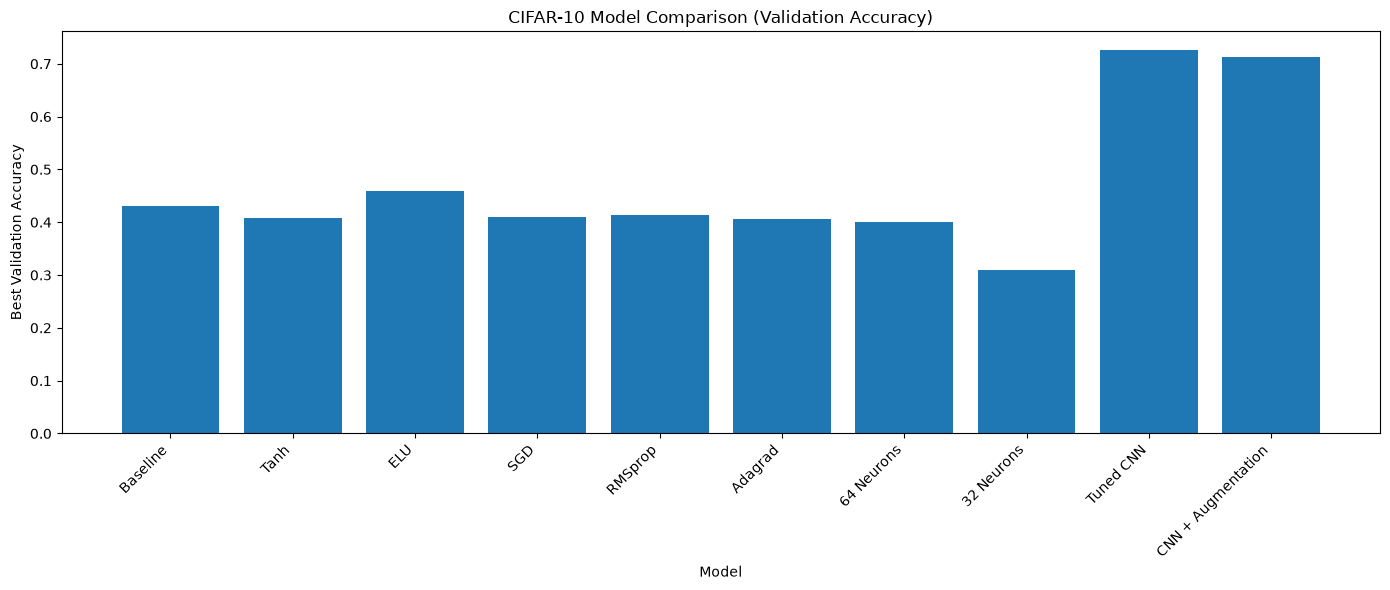

In [26]:
# ============================================================
# 21A. PLOT VALIDATION ACCURACY
# ============================================================

model_names = [
    result['name']
    for result in results
]

accuracies = [
    result['val_accuracy']
    for result in results
]

plt.figure(figsize=(14, 6))

plt.bar(
    model_names,
    accuracies
)

plt.ylabel("Best Validation Accuracy")
plt.xlabel("Model")
plt.title("CIFAR-10 Model Comparison (Validation Accuracy)")

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

## Select the Model and Evaluate Test Performance

This section selects the model with the highest validation accuracy and evaluates it using the reserved CIFAR-10 test dataset. The final test loss and accuracy provide an indication of how well the selected model classifies images it has not seen before.

In [27]:
# ============================================================
# 21B. SELECT A MODEL USING VALIDATION ACCURACY
# ============================================================

best_model_result = max(
    results,
    key=lambda result: result["val_accuracy"]
)

final_model = best_model_result["model"]

print("Selected model:", best_model_result["name"])
print(
    "Best validation accuracy:",
    f"{best_model_result['val_accuracy']:.4f}"
)

# Final evaluation: the test set is used only after model selection.
final_test_loss, final_test_accuracy = final_model.evaluate(
    test_images,
    test_labels,
    batch_size=64,
    verbose=1
)
print(f"Final test loss: {final_test_loss:.4f}")
print(f"Final test accuracy: {final_test_accuracy:.4f}")
print(f"Final test accuracy: {final_test_accuracy * 100:.2f}%")

Selected model: Tuned CNN
Best validation accuracy: 0.7252
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7065 - loss: 0.9330
Final test loss: 0.9330
Final test accuracy: 0.7065
Final test accuracy: 70.65%


## Generate a Confusion Matrix and Classification Report

This section examines the selected model's classification performance across all ten CIFAR-10 classes. The confusion matrix shows how often images from each class are correctly classified or mistaken for another class. The classification report provides precision, recall, F1-score and support for each category, giving a more detailed view of the model's strengths and weaknesses.

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


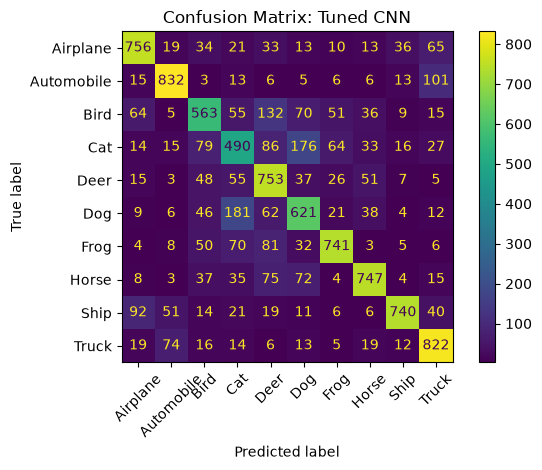

              precision    recall  f1-score   support

    Airplane     0.7590    0.7560    0.7575      1000
  Automobile     0.8189    0.8320    0.8254      1000
        Bird     0.6326    0.5630    0.5958      1000
         Cat     0.5131    0.4900    0.5013      1000
        Deer     0.6010    0.7530    0.6684      1000
         Dog     0.5914    0.6210    0.6059      1000
        Frog     0.7934    0.7410    0.7663      1000
       Horse     0.7847    0.7470    0.7654      1000
        Ship     0.8747    0.7400    0.8017      1000
       Truck     0.7419    0.8220    0.7799      1000

    accuracy                         0.7065     10000
   macro avg     0.7111    0.7065    0.7068     10000
weighted avg     0.7111    0.7065    0.7068     10000



In [28]:
# ============================================================
# 21C. CONFUSION MATRIX AND CLASSIFICATION METRICS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Generate predicted class probabilities.
test_probabilities = final_model.predict(
    test_images,
    batch_size=64,
    verbose=1
)

predicted_classes = np.argmax(test_probabilities, axis=1)
actual_classes = test_labels.ravel()

# Confusion matrix.
cm = confusion_matrix(
    actual_classes,
    predicted_classes,
    labels=np.arange(10)
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

cm_display.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title(
    f"Confusion Matrix: {best_model_result['name']}"
)
plt.tight_layout()
plt.show()

# Precision, recall, F1-score and support for every class.
print(
    classification_report(
        actual_classes,
        predicted_classes,
        labels=np.arange(10),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

## Compare Validation Accuracy and Training Time

This section compares each model's validation accuracy and training time to assess its performance and computational cost. The final test accuracy and test loss of the selected model are then reported separately. The test dataset is reserved for the final evaluation and is not used to select between candidate models.

In [29]:
# ============================================================
# 21D. COMPARE VALIDATION PERFORMANCE AND TRAINING TIME
# ============================================================

print(
    f"{'Model':<25}"
    f"{'Validation Acc.':>17}"
    f"{'Time (s)':>12}"
)
print("-" * 54)

for result in results:
    print(
        f"{result['name']:<25}"
        f"{result['val_accuracy']:>17.4f}"
        f"{result['training_time']:>12.2f}"
    )

# Report the final test result for the selected model only.
# The test set is not used to compare or select candidate models.
print("\nFinal evaluation of the selected model")
print(f"Selected model: {best_model_result['name']}")
print(
    f"Validation accuracy: "
    f"{best_model_result['val_accuracy']:.2%}"
)
print(f"Final test accuracy: {final_test_accuracy:.2%}")
print(f"Final test loss: {final_test_loss:.4f}")

Model                      Validation Acc.    Time (s)
------------------------------------------------------
Baseline                            0.4298       24.60
Tanh                                0.4078       25.61
ELU                                 0.4590       26.18
SGD                                 0.4096       16.06
RMSprop                             0.4136       24.17
Adagrad                             0.4054       22.62
64 Neurons                          0.4006       16.75
32 Neurons                          0.3088       13.47
Tuned CNN                           0.7252      173.55
CNN + Augmentation                  0.7124      141.29

Final evaluation of the selected model
Selected model: Tuned CNN
Validation accuracy: 72.52%
Final test accuracy: 70.65%
Final test loss: 0.9330


## Investigate Overfitting

This section plots the training and validation accuracy and loss for the selected model. Comparing these curves helps identify potential overfitting, which can occur when a model learns the training data well but performs less effectively on unseen data.

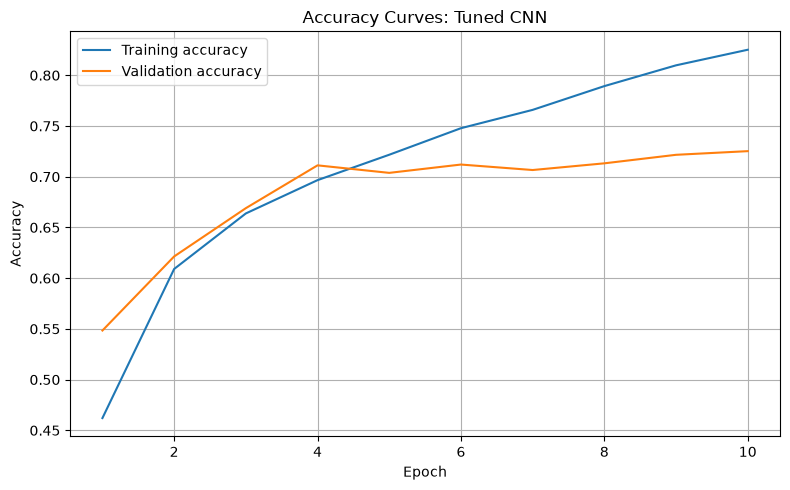

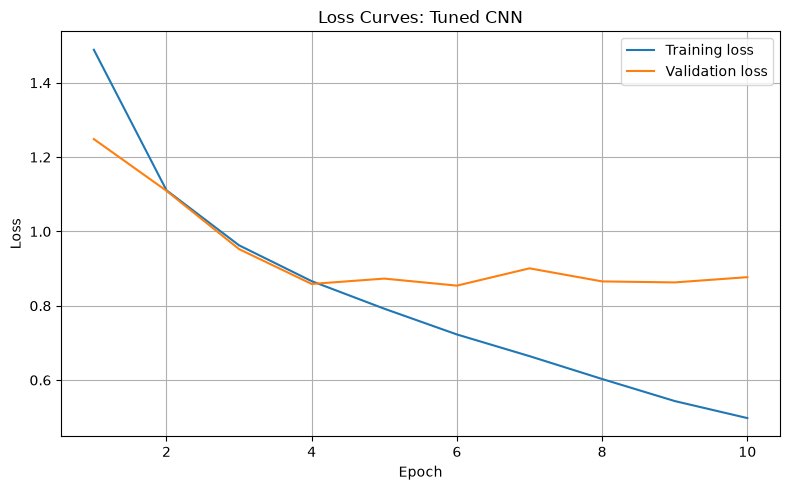


Overfitting analysis
Selected model: Tuned CNN
Final training accuracy: 82.52%
Final validation accuracy: 72.52%
Final training loss: 0.4978
Final validation loss: 0.8769
Training-validation accuracy gap: 10.00%


In [30]:
# ============================================================
# 21E. INVESTIGATE OVERFITTING
# ============================================================

selected_history = best_model_result["history"]
epochs_range = range(1, len(selected_history.history["loss"]) + 1)

# Accuracy comparison
plt.figure(figsize=(8, 5))
plt.plot(
    epochs_range,
    selected_history.history["accuracy"],
    label="Training accuracy"
)
plt.plot(
    epochs_range,
    selected_history.history["val_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Accuracy Curves: {best_model_result['name']}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Loss comparison
plt.figure(figsize=(8, 5))
plt.plot(
    epochs_range,
    selected_history.history["loss"],
    label="Training loss"
)
plt.plot(
    epochs_range,
    selected_history.history["val_loss"],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Loss Curves: {best_model_result['name']}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Print key values to support the overfitting discussion.
train_accuracy = selected_history.history["accuracy"]
val_accuracy = selected_history.history["val_accuracy"]
train_loss = selected_history.history["loss"]
val_loss = selected_history.history["val_loss"]

print("\nOverfitting analysis")
print(f"Selected model: {best_model_result['name']}")
print(f"Final training accuracy: {train_accuracy[-1]:.2%}")
print(f"Final validation accuracy: {val_accuracy[-1]:.2%}")
print(f"Final training loss: {train_loss[-1]:.4f}")
print(f"Final validation loss: {val_loss[-1]:.4f}")
print(
    f"Training-validation accuracy gap: "
    f"{train_accuracy[-1] - val_accuracy[-1]:.2%}"
)

The training and validation accuracy and loss curves were examined to assess the selected model's ability to generalise to unseen data.

Overfitting: If training accuracy continues to improve while validation accuracy stops improving or decreases, and validation loss begins to increase, this suggests that the model may be overfitting the training data.

Underfitting: If both training and validation accuracy remain low and both loss values remain relatively high, this may indicate that the model has not learnt the data's patterns sufficiently.

Reasonable generalisation: If training and validation accuracy improve together, their gap remains relatively small, and validation loss does not show a sustained increase, this suggests that the model generalises reasonably well.

Based on the observed curves, the conclusion should identify which pattern best describes the selected model and support it with the results printed above.

## Compare Training Times

This section displays the training duration of each model in a bar chart. The results help illustrate the computational cost of the different experiments and show how changes to the model configuration can affect training time.

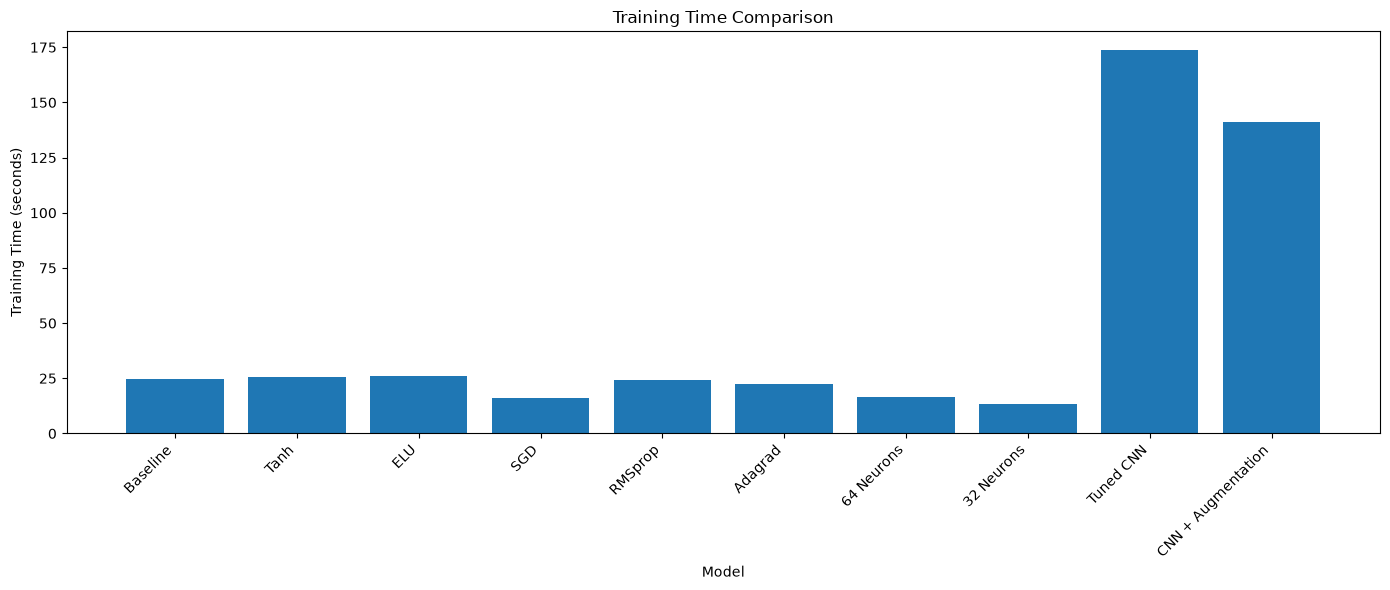

In [31]:
# ============================================================
# 22. PLOT TRAINING TIMES
# ============================================================

training_times = [
    result['training_time']
    for result in results
]

plt.figure(figsize=(14, 6))

plt.bar(
    model_names,
    training_times
)

plt.ylabel("Training Time (seconds)")
plt.xlabel("Model")
plt.title("Training Time Comparison")

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

##  Demonstrate a Prediction on an Unseen Test Image

This section uses the baseline model to classify a single image from the CIFAR-10 test dataset. The predicted class and confidence score are compared with the actual label to demonstrate how the model performs on an image that was not used during training. This provides a simple example of the model's classification behaviour on unseen data.

In [32]:
# ============================================================
# 23. DEMONSTRATE A BASELINE PREDICTION ON A TEST IMAGE
# ============================================================

# Select one image from the test dataset
sample_image = test_images[:1]
actual_label = test_labels[0][0]

# Predict the class of the image
probabilities = baseline['probability_model'].predict(sample_image, verbose=0)
predicted_label = np.argmax(probabilities[0])

# Display the prediction and actual class
print(f"Predicted class: {class_names[predicted_label]}")
print(f"Actual class: {class_names[actual_label]}")
print(f"Confidence: {probabilities[0][predicted_label]:.2%}")

Predicted class: Frog
Actual class: Cat
Confidence: 50.93%


## Create a Function to Display Predictions

This section defines a reusable function for displaying an image alongside its predicted class and confidence score. The function can be used to inspect individual predictions and compare the model's output with the expected class, making it easier to understand how the classifier performs on individual images.

In [33]:
# ============================================================
# 24. FUNCTION TO DISPLAY A PREDICTION
# ============================================================

def display_prediction(
    image,
    probabilities,
    title="Prediction"
):

    predicted_class = np.argmax(probabilities)

    confidence = np.max(probabilities)

    plt.figure(figsize=(6, 5))

    # CIFAR-10 images are RGB, so display without a grayscale colour map.
    plt.imshow(image)

    plt.xticks([])
    plt.yticks([])

    plt.title(
        f"{title}\n"
        f"Prediction: {class_names[predicted_class]}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.show()

    print("Predicted class:", class_names[predicted_class])
    print("Confidence:", f"{confidence:.2%}")

References

<small>Toronto.edu. (2026). CIFAR-10 and CIFAR-100 datasets. [online] Available at: https://cave.cs.toronto.edu/kriz/cifar.html [Accessed 18 Oct. 2026].</small>